# About this Notebook

This is a Python notebook. This is the notebook you'll use to run and create the analysis code on pickle data sets. Pickle files are created and premanufactured from ROOT files from MicroBooNE LAr experiment.

You should have access to: example_neutrino.ipynb, neutrino_function.py, data folder. You are free to modify neutrino_function.py or create your own plotting functions.

**IMPORTANT:** It is strongly recommended that only **one** student of a lab pair should edit this notebook and the files contained within the server directories. This is because both students cannot see the same live edit of the notebook or files at the same time, and it is easy to accidently overwrite each other.

Code that is commented out with two hashtags should be uncommented when in use.

# All imports

The basic libraries, you may import more if there are present on the server's environment. If you dont have these packages installed on your local machine, you can use **pip install X** or **pip3 install X** to start using them.

In [343]:
import numpy as np
import pickle

import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import Neutrino_functions

from math import *
import scipy as sci

# MACHINE LEARNING IMPORTS
import sklearn
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn import set_config

set_config(display="text")

# Opening the MC and data frames

In [344]:
# MC
MC_file = './data/MC_EXT_flattened.pkl'

# Data
data_file = './data/data_flattened.pkl'


# Open file as pandas dataframe
MC_EXT = pd.read_pickle(MC_file)
data = pd.read_pickle(data_file)

# removing 'Subevent' from data
MC_EXT = MC_EXT.drop('Subevent', axis = 1)
data = data.drop('Subevent', axis = 1)

# You can display the dataframe by uncommenting these lines and running the cell

In [345]:
# Uncomment these lines to display the dataframes
pd.set_option('display.max_columns', 100)
# displays top 10 results.
data.head(10)

,_closestNuCosmicDist,trk_len_v,trk_distance_v,category,topological_score,trk_sce_end_z_v,trk_sce_end_y_v,trk_sce_end_x_v,trk_score_v,trk_llr_pid_score_v,trk_sce_start_z_v,trk_sce_start_y_v,trk_sce_start_x_v,reco_nu_vtx_sce_x,reco_nu_vtx_sce_y,reco_nu_vtx_sce_z,trk_energy_tot,trk_range_muon_mom_v,trk_mcs_muon_mom_v
0,48.170196,230.178085,0.289455,0,0.932121,662.713745,-10.419758,0.564317,1.0,0.981798,443.558472,-71.411057,32.10228,32.137272,-71.675980,443.439148,10000.021584,0.624387,0.672995
1,48.170196,19.862617,20.065849,0,0.932121,467.605438,-41.015533,40.286861,0.460725,0.722245,455.0065,-55.723381,36.461731,32.137272,-71.675980,443.439148,10000.021584,0.145945,0.159
2,177.083498,174.338699,0.057629,0,0.588847,978.765259,9.115969,153.437668,0.999995,0.970214,852.828674,-36.029785,42.856102,42.869896,-35.978130,852.848938,0.629191,0.502137,0.551996
3,0.067737,264.553223,196.515564,0,0.002079,998.799072,18.552534,225.164139,1.0,0.977688,797.282776,63.213791,63.001648,160.463943,-113.297066,772.441833,10000.778217,0.700354,0.627999
4,36.361293,493.096283,0.465464,0,0.983048,865.795166,-56.678547,80.313004,1.0,0.990403,408.639801,96.316406,141.032898,141.039246,96.385994,408.178772,1.296849,1.220361,1.124005
5,127.613429,181.327194,0.272344,0,0.021950,264.979065,92.158607,255.202988,0.999972,0.958479,230.559982,-81.870941,221.46637,221.349503,-81.868439,230.311829,9999.794868,0.517367,0.527997
6,127.613429,10.863928,0.334015,0,0.021950,226.903671,-91.896515,218.480057,0.791141,-0.287616,229.998383,-81.993217,221.4086,221.349503,-81.868439,230.311829,9999.794868,0.114687,0.102
7,101.562292,8.869122,265.905823,0,0.036152,110.97657,81.228905,30.3652,0.011572,0.133134,114.274597,86.827835,36.310745,170.431870,59.736755,340.503021,9999.221455,0.106222,0.101
8,181.173178,168.925873,0.349405,0,0.517549,517.184326,67.922836,156.103348,0.999998,0.959285,406.7724,114.33268,40.269585,40.016575,114.483635,406.585693,9999.828041,0.490352,0.428998
9,162.177990,47.523987,0.030297,0,0.336266,892.599304,-59.251465,37.77512,0.93185,0.761358,870.96521,-33.337875,71.00219,71.004707,-33.363049,870.948181,0.286233,0.220104,0.228


In [346]:
MC_EXT.head(10)

,_closestNuCosmicDist,trk_len_v,trk_distance_v,category,topological_score,trk_sce_end_z_v,trk_sce_end_y_v,trk_sce_end_x_v,trk_score_v,trk_llr_pid_score_v,trk_sce_start_z_v,trk_sce_start_y_v,trk_sce_start_x_v,reco_nu_vtx_sce_x,reco_nu_vtx_sce_y,reco_nu_vtx_sce_z,trk_energy_tot,trk_range_muon_mom_v,trk_mcs_muon_mom_v,weight,true_E,true_L,true_muon_mom
0,124.478148,225.284348,1.286398,21,0.994485,510.146088,-19.997118,191.864334,1.0,0.977081,343.433655,35.865448,54.776821,53.900658,36.203041,342.578735,1.164239,0.613618,0.624997,0.000002,1.371928,438.602722,0.607686
1,124.478148,7.850903,131.947891,21,0.994485,389.239197,46.669083,183.160797,0.041434,0.486446,382.998871,47.109879,178.486572,53.900658,36.203041,342.578735,1.164239,0.101568,0.093,0.000002,1.371928,438.602722,0.607686
2,141.086923,251.017548,0.025229,5,0.007706,766.055969,-50.159794,172.77446,1.0,0.972468,658.480286,117.427391,20.797407,20.804905,117.408989,658.495789,9999.989363,0.670372,0.740995,0.158957,1.798278,440.984772,0.727932
3,10.511966,58.736591,10.511966,4,0.066952,213.629105,117.414757,88.746597,0.929871,0.870984,224.018387,60.914005,78.242538,78.443840,50.530334,223.597870,9999.441230,0.246837,0.234,0.192390,0.777679,438.613037,0.489567
4,10.511966,9.962337,3.888895,4,0.066952,235.423004,46.921162,80.265305,0.372258,0.404711,226.829147,51.903919,80.192444,78.443840,50.530334,223.597870,9999.441230,0.11096,0.131,0.192390,0.777679,438.613037,0.489567
5,147.929810,289.265442,0.152002,5,0.515178,1031.704712,52.0289,83.527153,1.0,0.9848,761.951172,-6.10771,1.388844,1.357146,-6.141214,761.806335,9999.934871,0.755327,0.761996,0.986006,1.214413,431.785278,0.826329
6,96.691013,56.727428,27.846855,21,0.998477,1036.508911,-38.234692,19.931959,0.065278,0.902933,992.340698,-65.519211,22.75659,25.337120,-80.776207,969.163696,10000.275867,0.242116,0.188,0.158957,1.857195,463.048309,1.271057
7,96.691013,67.758522,0.264366,21,0.998477,1036.692261,-78.989571,24.593576,0.966078,0.940751,969.034668,-81.002808,25.39159,25.337120,-80.776207,969.163696,10000.275867,0.267746,0.346999,0.158957,1.857195,463.048309,1.271057
8,96.691013,25.262609,7.398347,21,0.998477,987.487305,-65.503288,5.5114,0.082593,0.79802,972.884705,-76.234444,20.853903,25.337120,-80.776207,969.163696,10000.275867,0.161958,0.099,0.158957,1.857195,463.048309,1.271057
9,106.679589,73.540779,0.226748,5,0.040650,769.010193,110.767021,45.539276,0.950805,0.911611,759.31604,53.225922,1.124355,1.250130,53.412140,759.350220,9999.371950,0.280941,0.384999,0.194167,0.890958,445.648376,0.478177


In [347]:
MC_EXT.info()

<class 'pandas.DataFrame'>
RangeIndex: 555624 entries, 0 to 555623
Data columns (total 23 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   _closestNuCosmicDist  555624 non-null  float64
 1   trk_len_v             555624 non-null  object 
 2   trk_distance_v        555624 non-null  object 
 3   category              555624 non-null  int64  
 4   topological_score     555624 non-null  float32
 5   trk_sce_end_z_v       555624 non-null  object 
 6   trk_sce_end_y_v       555624 non-null  object 
 7   trk_sce_end_x_v       555624 non-null  object 
 8   trk_score_v           555624 non-null  object 
 9   trk_llr_pid_score_v   555624 non-null  object 
 10  trk_sce_start_z_v     555624 non-null  object 
 11  trk_sce_start_y_v     555624 non-null  object 
 12  trk_sce_start_x_v     555624 non-null  object 
 13  reco_nu_vtx_sce_x     555624 non-null  float32
 14  reco_nu_vtx_sce_y     555624 non-null  float32
 15  reco_nu_vtx

# Machine learning for Particle Classification

First, look at a sub-sample of our Monte Carlo data.

In [348]:
# Reduce the amount of data for visualisation purposes
MC_EXT_VIS = MC_EXT.sample(int(len(MC_EXT)/10))

# Resetting the index
MC_EXT_VIS.reset_index(drop=True, inplace=True)

# Removing high energy (unphysical) monte carlo results
MC_EXL_VIS = MC_EXT_VIS.drop(MC_EXT_VIS[MC_EXT_VIS.trk_energy_tot > 2].index, inplace = True)

# Resetting the index again
MC_EXT_VIS.reset_index(drop=True, inplace=True)

# Displaying dataframe
print("Length of new data sample: {}".format(len(MC_EXT_VIS)))
MC_EXT_VIS.head(20)


Length of new data sample: 14358


,_closestNuCosmicDist,trk_len_v,trk_distance_v,category,topological_score,trk_sce_end_z_v,trk_sce_end_y_v,trk_sce_end_x_v,trk_score_v,trk_llr_pid_score_v,trk_sce_start_z_v,trk_sce_start_y_v,trk_sce_start_x_v,reco_nu_vtx_sce_x,reco_nu_vtx_sce_y,reco_nu_vtx_sce_z,trk_energy_tot,trk_range_muon_mom_v,trk_mcs_muon_mom_v,weight,true_E,true_L,true_muon_mom
0,68.606101,6.502349,0.583278,21,0.998789,477.243622,-60.369354,45.782177,0.71051,-0.105647,474.946869,-55.1702,42.781322,42.491848,-54.818497,475.305542,1.099621,0.094966,0.126,0.158957,1.528735,456.304352,0.231769
1,98.025576,56.559021,0.468357,21,0.499215,594.699585,21.426004,238.64447,0.931909,0.872476,612.589294,-12.480409,198.582947,198.749008,-12.112874,612.308960,0.509989,0.241719,0.18,0.158957,1.013842,462.723572,0.244730
2,29.464672,118.350861,2.129983,21,0.999964,382.32843,18.732185,209.823685,0.999606,0.964591,292.337799,-31.524019,153.197556,152.183319,-32.374893,290.633270,1.073334,0.380306,0.341999,0.158957,1.275185,459.983856,0.383376
3,46.228000,237.467957,0.610482,21,0.993323,821.197632,-50.340134,139.374146,1.0,0.97732,627.132751,-0.332144,12.986484,12.701608,-0.294362,626.600952,0.827605,0.640449,0.659996,0.158957,1.045238,451.189636,0.670266
4,126.603928,18.070255,0.846731,21,0.774643,875.247314,13.233522,238.014175,0.85888,0.563915,872.299072,10.399688,220.539841,219.681488,10.228541,872.402100,0.575727,0.140335,0.136,0.186070,0.906391,470.252594,0.337226
5,65.105409,60.874592,0.612079,21,0.976390,537.236206,69.807785,45.118553,0.980351,0.898177,479.073059,61.605106,60.283169,60.238453,61.872028,478.522430,0.528699,0.251834,0.252,0.158957,0.762734,452.057343,0.251844
6,115.880487,138.35611,0.630971,21,0.563824,941.233154,-16.704609,131.142899,0.99864,0.937401,894.997925,35.289822,249.936905,250.474319,35.639133,894.890930,0.533051,0.423887,0.449998,0.198064,0.708859,452.848846,0.420492
7,150.179479,32.129688,9.935726,21,0.984670,90.280907,117.619118,24.530331,0.02093,0.813453,63.25391,104.937393,33.945286,35.727612,102.216309,53.859039,0.997407,0.181026,0.13,0.158957,1.382433,441.671814,0.306830
8,165.553495,105.942848,0.172738,5,0.414581,0.052511,111.302269,171.081543,0.999675,0.958872,65.876038,29.202629,170.548019,170.602463,29.107590,66.008209,0.672288,0.353135,0.302,0.158957,1.129328,451.987396,0.532974
9,41.539281,70.72789,0.353484,21,0.093573,453.808136,20.590519,223.76915,0.915812,0.926987,507.973419,60.78569,203.743149,203.722916,60.447922,508.102936,0.385208,0.274539,0.272,0.184846,0.890404,435.032349,0.271956


# Exercise 5 Data Visualisation
Lets visualise some of the variables using *seaborn*

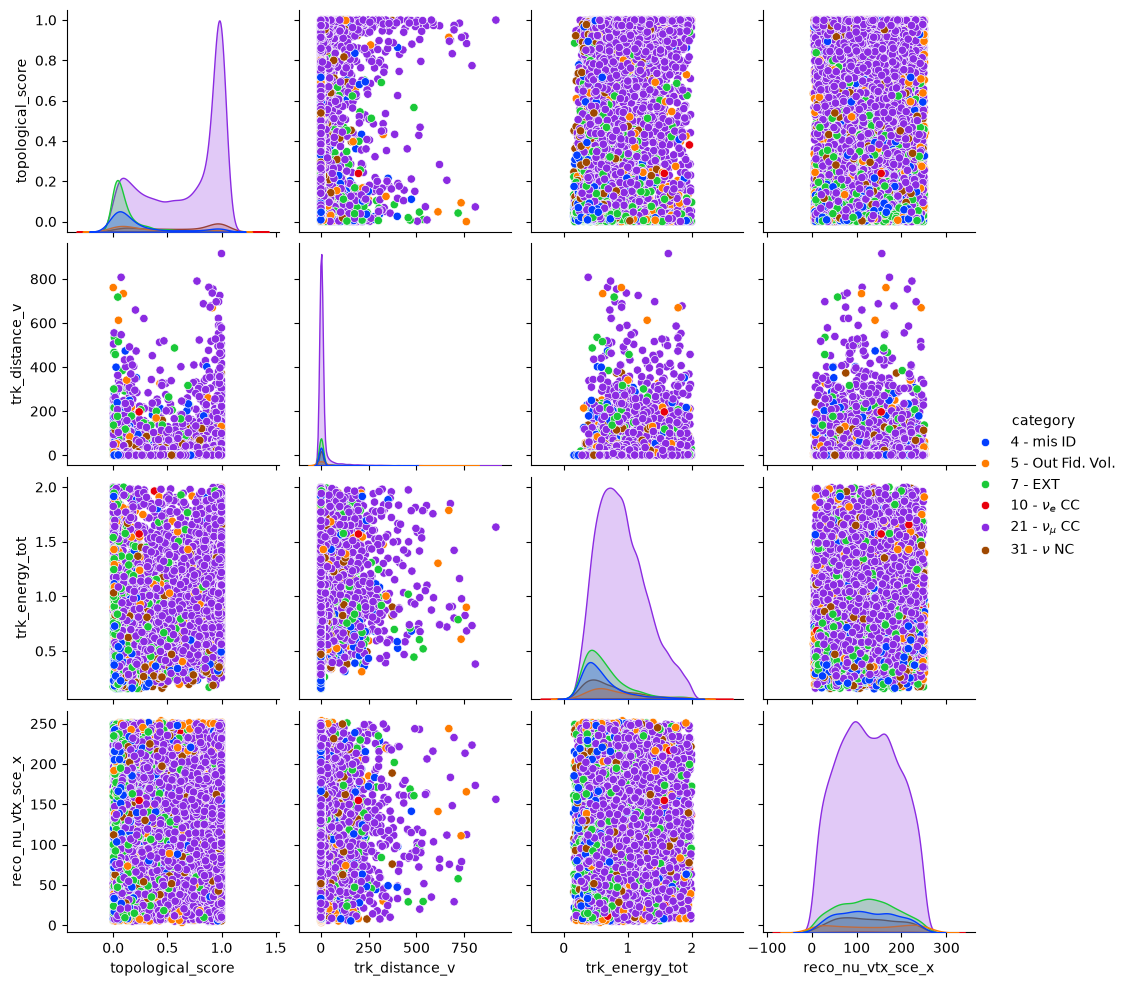

In [349]:
# Visualising a couple of variables.
variable_list = ['category', 'topological_score', 'trk_distance_v', 'trk_energy_tot', 'reco_nu_vtx_sce_x']

# List of categories in text
ptype = [r"mis ID", r"Out Fid. Vol.", r"EXT", r"$\nu_e$ CC", r"$\nu_{\mu}$ CC", r"$\nu$ NC"]

# Keep category colours identical in both pairplots.
category_palette = dict(zip([4, 5, 7, 10, 21, 31], sns.color_palette('bright', 6)))

# Plot data
fig = sns.pairplot(MC_EXT_VIS[variable_list], hue = 'category', palette = category_palette)

# Change location of legend
fig._legend.set_bbox_to_anchor((1.05, 0.5))

# Add Category number and type to legend
for t, l in zip(fig._legend.texts, ptype):
   t.set_text(str(t.get_text()) + " - " + str(l))

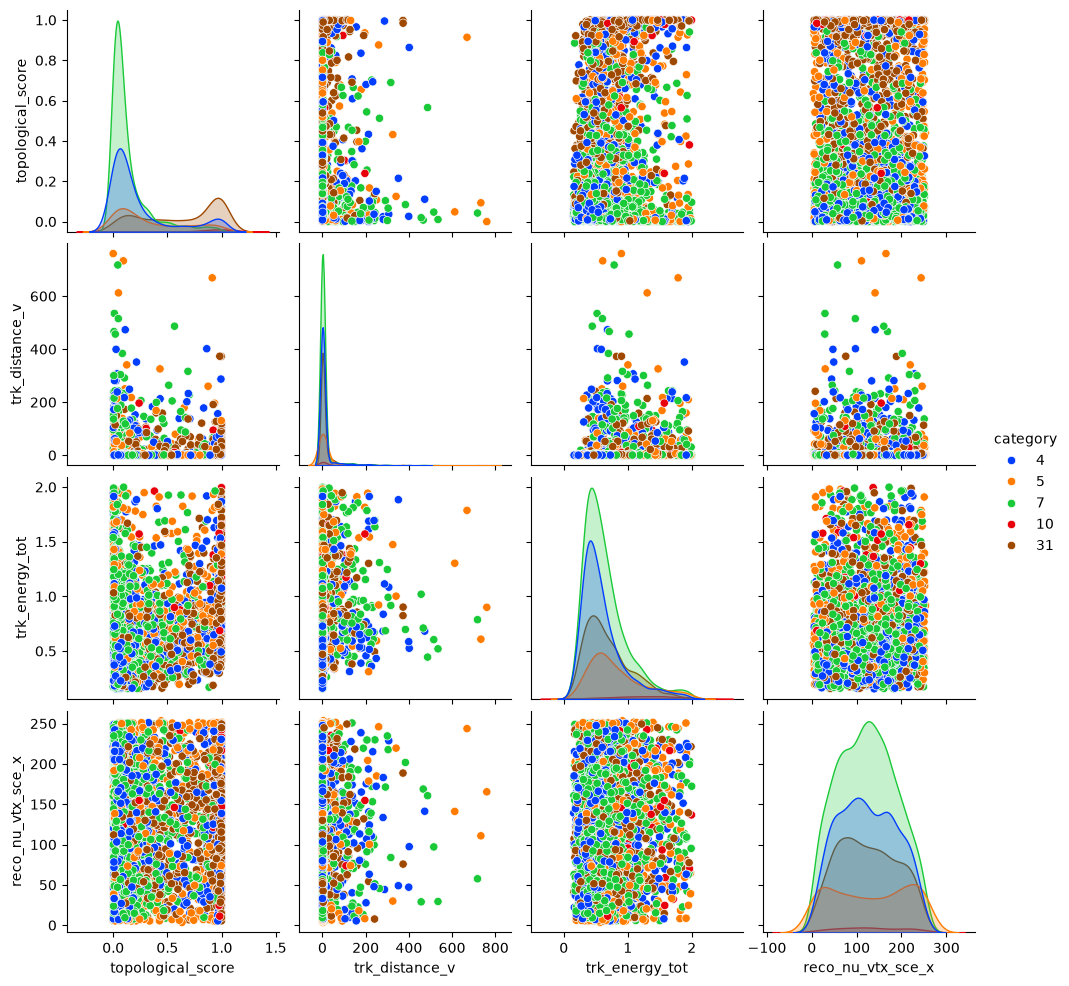

In [350]:
MC_EXT_VIS_background = MC_EXT_VIS.copy(deep=True)

MC_EXT_VIS_background = MC_EXT_VIS_background[
    MC_EXT_VIS_background['category'] != 21
]

sns.pairplot(
    MC_EXT_VIS_background[variable_list],
    hue='category',
    palette=category_palette
)

In [351]:
# Plot your background events using sns.pairplot

# List of categories (excluding signal) in text
ptype_no_mu = [r"mid ID", r"Out Fid. Vol.", r"EXT", r"$\nu_e$ CC", r"$\nu$ NC"]


In [352]:
# Make sure to delete dataframe copies if you no longer need them!
del MC_EXT_VIS

### Exercise 5: Background trends and visualisation

Removing category 21 makes the background distributions easier to inspect. Compare where each category concentrates in topological score, distance to the vertex, reconstructed energy and vertex position. Describe the trends visible in your plots; apparent separation does not by itself establish a correlation or a reliable selection cut.

Trends can still be difficult to see because points overlap, category sizes differ, extreme values stretch the axes, and useful relationships may involve more than two variables. Smaller transparent markers and an equal-sized sample from each background category help compare shapes. Equal sampling changes the relative category counts, so this sample is for visualisation only, not for energy spectra, purity or efficiency calculations.


### Bonus 1: Make background patterns clearer

Use up to 1,000 rows per category, taking the same number from every category. A fixed random seed makes this visualisation reproducible. Keep the original background dataframe unchanged and retain the original category colours.


Rows per category in the visualisation sample:
category
4     44
5     44
7     44
10    44
31    44
Name: count, dtype: int64


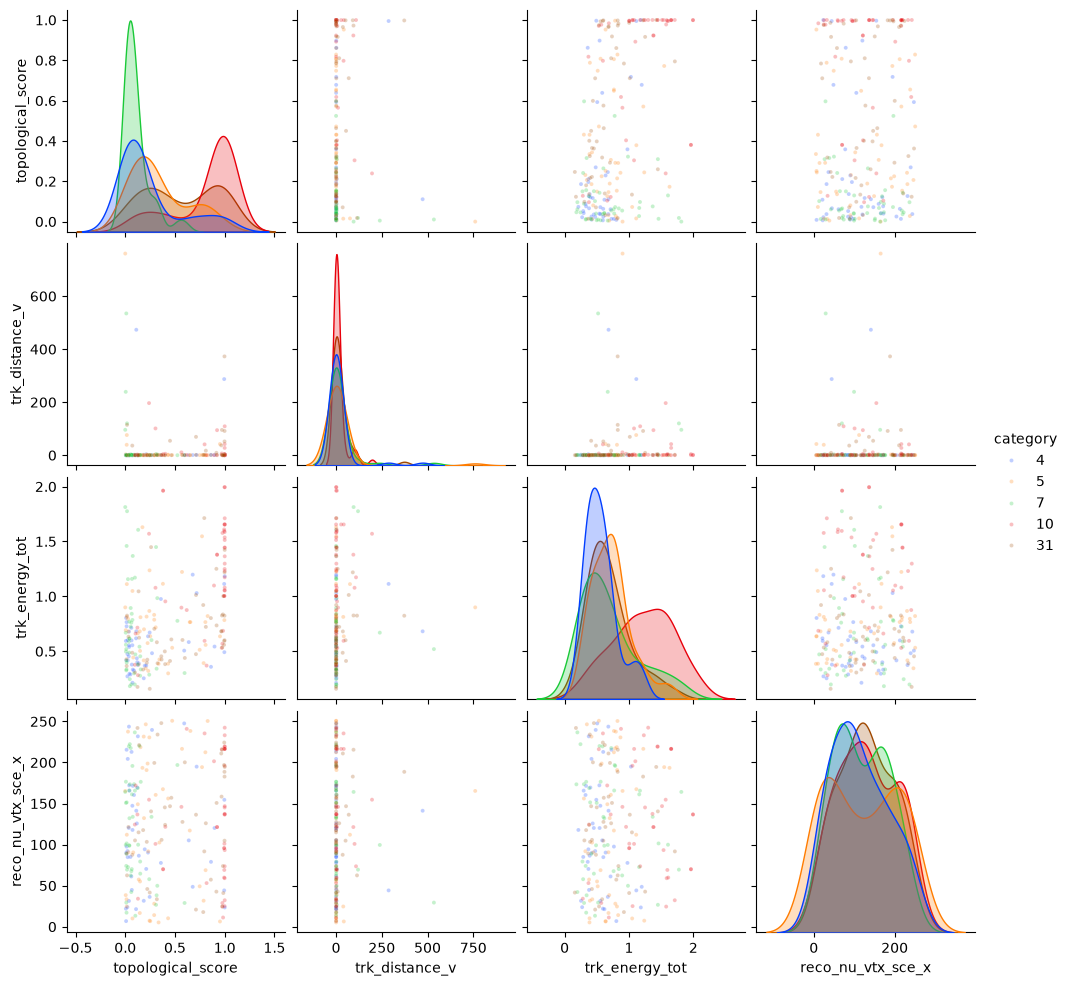

In [353]:
# Create a balanced sample for visualisation only.
background_counts = MC_EXT_VIS_background['category'].value_counts()
rows_per_category = min(1000, int(background_counts.min())) if not background_counts.empty else 0

if rows_per_category == 0:
    raise ValueError('No background rows available. Run the preceding Exercise 5 cells first.')

background_balanced = pd.concat([
    group.sample(n=rows_per_category, random_state=1)
    for _, group in MC_EXT_VIS_background.groupby('category', sort=True)
], ignore_index=True)

print('Rows per category in the visualisation sample:')
print(background_balanced['category'].value_counts().sort_index())

background_variables = [name for name in variable_list if name != 'category']
fig_background_clear = sns.pairplot(
    background_balanced[background_variables + ['category']],
    vars=background_variables,
    hue='category',
    palette=category_palette,
    diag_kind='kde',
    plot_kws={'s': 8, 'alpha': 0.25},
    diag_kws={'fill': True, 'alpha': 0.25, 'warn_singular': False}
)
plt.show()


### Bonus 2: Explore additional variables

Add track length, track/shower score and the particle-identification score. Track length may distinguish different track populations; the track score describes whether an object looks track-like rather than shower-like; the PID score helps distinguish particle hypotheses such as muons and protons. Compare their distributions and pairwise relationships across background categories. Record which categories overlap and whether the added variables reveal clearer separation.


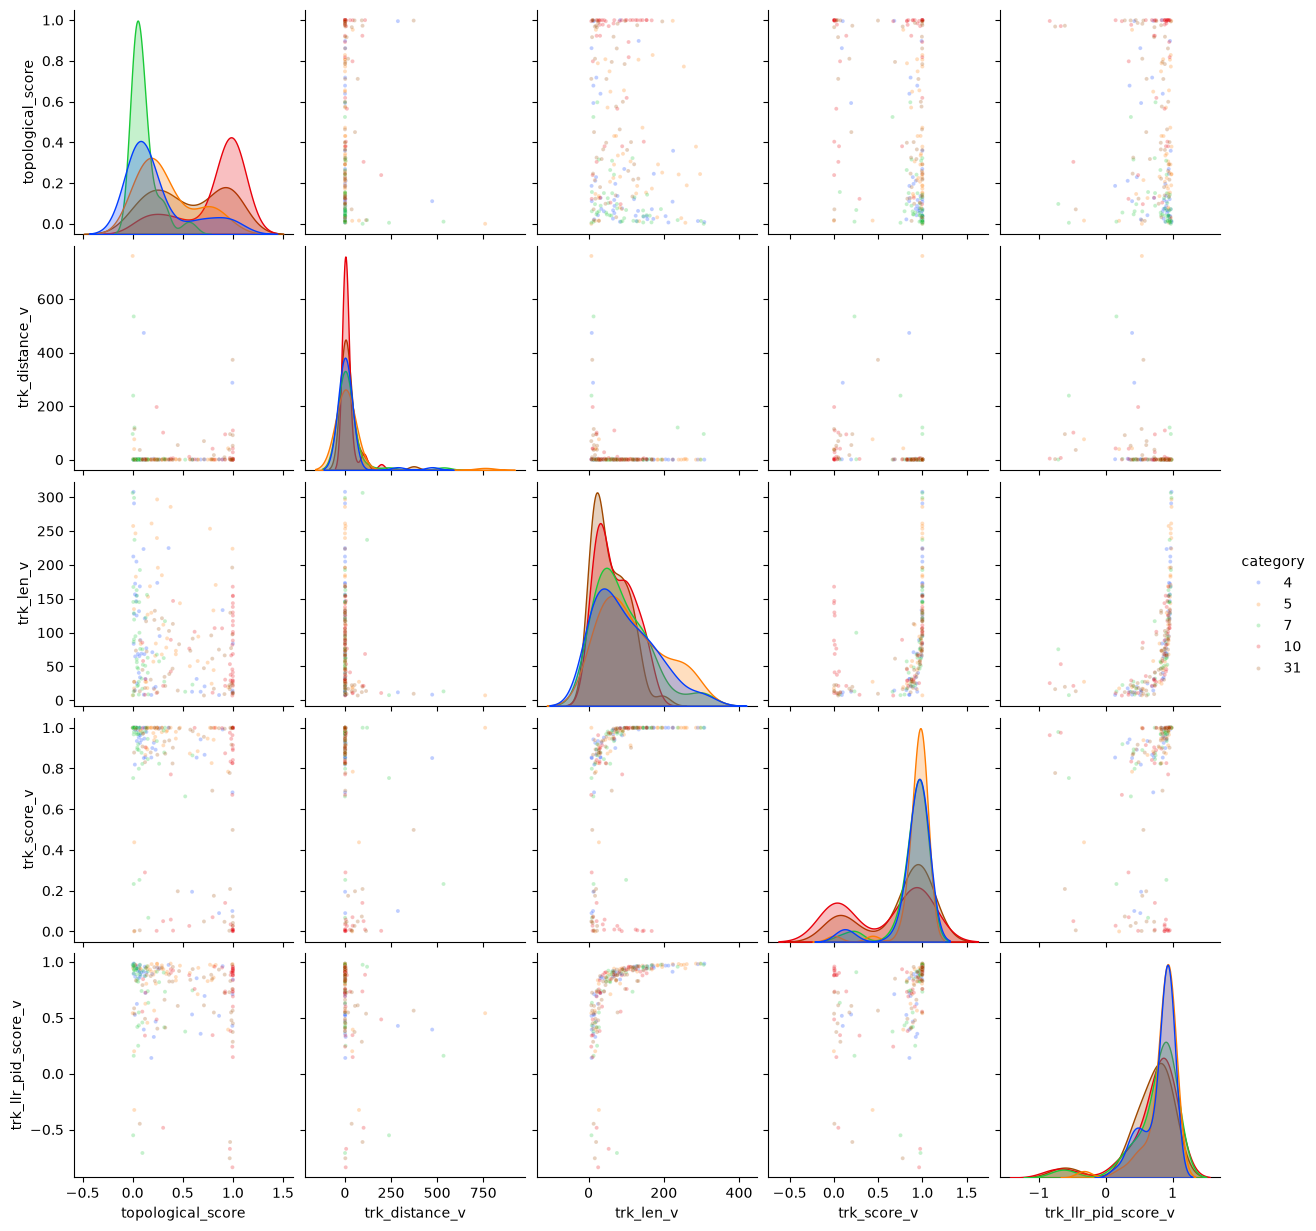

In [354]:
extra_variables = [
    'topological_score',
    'trk_distance_v',
    'trk_len_v',
    'trk_score_v',
    'trk_llr_pid_score_v'
]

fig_background_extra = sns.pairplot(
    background_balanced[extra_variables + ['category']],
    vars=extra_variables,
    hue='category',
    palette=category_palette,
    diag_kind='kde',
    plot_kws={'s': 8, 'alpha': 0.25},
    diag_kws={'fill': True, 'alpha': 0.25, 'warn_singular': False}
)
plt.show()


# Exercise 6: Random Forest applications

Here we shall modify the shape of our data for its usage in a decision tree, then apply the *RandomForest* method from the skikit-learn package.

In [355]:
# Adjust data shape
features = ['_closestNuCosmicDist', 'trk_len_v', 'trk_distance_v', 'topological_score', 'trk_sce_end_z_v', 'trk_sce_end_y_v', 'trk_sce_end_x_v', 'trk_score_v', 'trk_llr_pid_score_v', 'trk_sce_start_z_v', 'trk_sce_start_y_v', 'trk_sce_start_x_v', 'reco_nu_vtx_sce_x', 'reco_nu_vtx_sce_y', 'reco_nu_vtx_sce_z', 'trk_energy_tot']
output = ['category']

# Setup new database, NEED MORE VALUES
MC_EXT_ML = MC_EXT.copy(deep = True)
MC_EXT_ML = MC_EXT.sample(int(len(MC_EXT)/10))


# Remove muon neutrino and electron neutrino events.
MC_EXT_ML = MC_EXT_ML[~MC_EXT_ML['category'].isin([10, 21])].copy()

# Print length of dataframe,, with length N
print("Length of MC dataframe: ", len(MC_EXT_ML))

Length of MC dataframe:  32050


In [356]:
from sklearn.preprocessing import StandardScaler

# Setting up input parameters for random forest.
X = MC_EXT_ML[features]
y = np.array(MC_EXT_ML['category'])

# Display shape of X and y, should be (N, 16) (N) where is number of samples.
print("(X) (y) shape:")
print(X.shape, y.shape)

# Then split the data up into a "training set" and "test set" using train_test_split.
# Keep the random_state=1 in your arguments
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y) # 80/20 training/test split

# Balance training classes by randomly undersampling to the smallest class.
# Keep the test set and the original physics samples at their natural proportions.
training_labels = pd.Series(y_train).reset_index(drop=True)
training_counts = training_labels.value_counts().sort_index()
if set(training_counts.index) != {4, 5, 7, 31}:
    raise ValueError('Expected all four background classes: 4, 5, 7 and 31.')
rows_per_class = int(training_counts.min())
balanced_positions = np.concatenate([
    training_labels[training_labels.eq(category)].sample(
        n=rows_per_class, random_state=1
    ).index.to_numpy()
    for category in training_counts.index
])
# Shuffle selected positions while preserving feature-label alignment.
balanced_positions = np.random.default_rng(1).permutation(balanced_positions)
x_train = x_train.iloc[balanced_positions].copy()
y_train = np.asarray(y_train)[balanced_positions]
print('Training class counts before balancing:')
print(training_counts.to_string())
print('Training class counts after balancing:')
print(pd.Series(y_train).value_counts().sort_index().to_string())

# Standardise features using training-set statistics only.
# Apply the same transformation to the test set; keep category labels unchanged.
scaler = StandardScaler()
x_train = pd.DataFrame(
    scaler.fit_transform(x_train), columns=features, index=x_train.index
)
x_test = pd.DataFrame(
    scaler.transform(x_test), columns=features, index=x_test.index
)

# Print the shape, should now be 
print("\n(x_train) (y_train) shape: ")
print(x_train.shape, y_train.shape)

print("\n(x_test) (y_test) shape: ")
print(x_test.shape, y_test.shape)


(X) (y) shape:
(32050, 16) (32050,)
Training class counts before balancing:
4      4080
5      7688
7     10855
31     3017
Training class counts after balancing:
4     3017
5     3017
7     3017
31    3017

(x_train) (y_train) shape: 
(12068, 16) (12068,)

(x_test) (y_test) shape: 
(6410, 16) (6410,)


Produce your randomforest model and fit it (dont worry, there is no explicit output, but make sure you haven't made your model too big! It shouldn't take any more than a couple of minutes at most to fit).

In [357]:
# Produce randomforest classifier model and fit to training data
# Keep the random_state=1 in your arguments
rf = RandomForestClassifier(random_state=1, n_estimators=1000, max_depth=8, min_samples_split=5, min_samples_leaf=2,
                           criterion='gini', n_jobs=-1)

# Fitting takes the input and "truth" data for classification purposes
rf.fit(x_train, y_train)

RandomForestClassifier(max_depth=8, min_samples_leaf=2, min_samples_split=5,
                       n_estimators=1000, n_jobs=-1, random_state=1)

Test the accuracies of your results:

In [358]:
# Produce predictions for the classification of your training dataset using your model:
y_pred = rf.predict(x_train)

# plot the accuracies of said predictions
print("Accuracy on training dataset:",metrics.accuracy_score(y_train, y_pred))
rf_acc_train = metrics.accuracy_score(y_train, y_pred)
y_pred = rf.predict(x_test)
print("Accuracy on testing dataset:",metrics.accuracy_score(y_test, y_pred))
rf_acc_test = metrics.accuracy_score(y_test, y_pred)

Accuracy on training dataset: 0.6788200198873052
Accuracy on testing dataset: 0.6118564742589704


If your training accuracy is similar to your testing accuracy, this demonstrates that you haven't overfit your data!

#### Confusion matrix and variable importance

Produce a confusion matrix for your model to quantify its ability to predict your different interaction types.

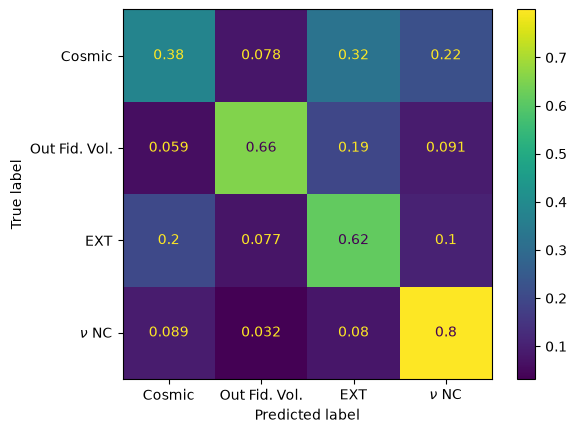

In [359]:
# For labelling your confusion matrix
ptype_no_mu_e = [r"Cosmic", r"Out Fid. Vol.", r"EXT", r"$\nu$ NC"]

# plot your confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[4, 5, 7, 31], normalize = 'true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=ptype_no_mu_e)
disp.plot()
plt.show()

Plot the importance of your different parameters.

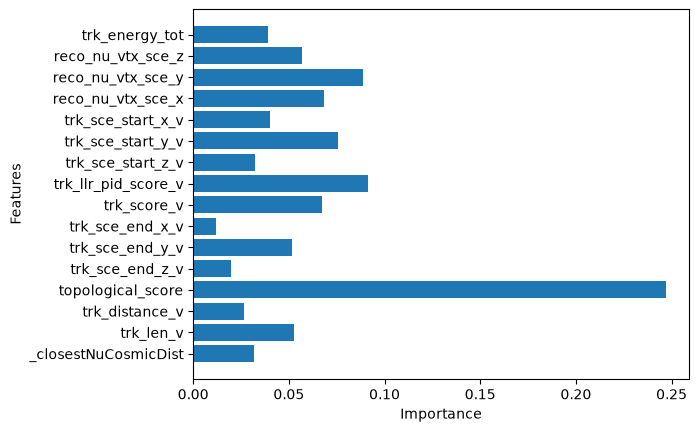

In [360]:
# Plot importance
importance = rf.feature_importances_
ytix = features

plt.barh(range(16), importance)
plt.yticks(range(16), features)
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()


# Neutrino_functions.py

You are given access to a couple of template functions provided within Neutrino_functions.py, which may be helpful in completing this lab. One such function is 'Neutrino_functions.histogram_plot', which can be seen below, but you can create your own functions if you wish.

In [361]:
#This command shows what input you should give the plotting function. The inputs with =None can be left out when calling the function
help(Neutrino_functions.histogram_plot)

Help on function histogram_plot in module Neutrino_functions:

histogram_plot(
    MC_frame,
    variable,
    bins,
    name,
    scaling,
    xlims=[],
    plot_fig=True,
    plot_data=False,
    logscale=None,
    dataFrame=None,
    Stat_func=None
)
    MC_frame: pandas dataframe - MC dataframe
    variable: string - name of the variable
    bins: int - number of bins
    name: string - name of the plot. The plot is saved
    scaling: array/list - weights you want to apply on MC data
    plot_data: boolean - if True then plots data as well
    logscale: boolean - if True then y axis is log scale
    dataFrame: pandas dataframe - data dataframe



# Exercise 7: Selection Cuts and Histogram plotting

Modify selection cuts. Remember to cut the same variables in both data sets.

In [362]:
# Preserve uncut samples across repeated runs of Exercise 7.
# Refresh these backups after reloading data if a new baseline is required.
if 'MC_EXT_original' not in globals():
    MC_EXT_original = MC_EXT.copy(deep=True)
if 'data_original' not in globals():
    data_original = data.copy(deep=True)


### Energy histogram before the energy cut


In [ ]:
# Balance categories for shape comparisons only; preserve physics samples.
def balanced_histogram_sample(frame):
    counts = frame['category'].value_counts()
    if counts.empty:
        raise ValueError('No rows available for the histogram.')
    rows_per_category = int(counts.min())
    sample = pd.concat([
        group.sample(n=rows_per_category, random_state=1)
        for _, group in frame.groupby('category', sort=True)
    ], ignore_index=True)
    print('Histogram rows per category:')
    print(sample['category'].value_counts().sort_index().to_string())
    return sample

MC_hist_before = balanced_histogram_sample(MC_EXT_original)

# Plot reconstructed neutrino energy before the high-energy cut.
category_palette = dict(zip([4, 5, 7, 10, 21, 31], sns.color_palette('bright', 6)))
category_names = {4: 'Mis-ID', 5: 'Out Fid. Vol.', 7: 'EXT',
                  10: 'Electron neutrino CC', 21: 'Muon neutrino CC', 31: 'Neutrino NC'}
fig, ax = plt.subplots(figsize=(12, 7))
sns.histplot(data=MC_hist_before, x='trk_energy_tot',
             hue='category', palette=category_palette, 
             multiple='stack', bins=23, ax=ax)
ax.set_title('Before the high-energy cut')
ax.set_xlabel('Reconstructed neutrino energy (GeV)')
ax.set_ylabel('Entries (equal category sample sizes)')
legend = ax.get_legend()
if legend is not None:
    for text in legend.get_texts():
        category = int(text.get_text())
        text.set_text(f'{category}: {category_names[category]}')
plt.tight_layout()
plt.show()


### Remove high-energy entries
Apply the same adjustable reconstructed-energy upper limit to MC and real data. Original samples are retained.


In [364]:
# Remove high reconstructed-energy entries using the same limit for MC and data.
# The initial 2 GeV limit matches Exercise 5; adjust it for the analysis range.
energy_upper_cut = 2.0  # GeV

def apply_energy_cut(frame):
    energy = pd.to_numeric(frame['trk_energy_tot'], errors='coerce')
    keep = np.isfinite(energy) & (energy <= energy_upper_cut)
    return frame.loc[keep].copy()

# Preserve the original samples so the threshold can be changed and rerun.
MC_EXT_energy_selected = apply_energy_cut(MC_EXT_original)
data_energy_selected = apply_energy_cut(data_original)

for name, original, selected in [
    ('MC + EXT', MC_EXT_original, MC_EXT_energy_selected),
    ('Data', data_original, data_energy_selected)
]:
    print(f'{name}: {len(original)} rows before, {len(selected)} after, '
          f'{len(original) - len(selected)} removed')

# Use energy-selected samples for subsequent analysis.
MC_EXT = MC_EXT_energy_selected.copy()
data_frame = data_energy_selected.copy()


MC + EXT: 555624 rows before, 144211 after, 411413 removed
Data: 119970 rows before, 28808 after, 91162 removed


### Energy histogram after the energy cut


In [ ]:
MC_hist_after = balanced_histogram_sample(MC_EXT_energy_selected)

# Plot reconstructed neutrino energy after the high-energy cut.
category_palette = dict(zip([4, 5, 7, 10, 21, 31], sns.color_palette('bright', 6)))
category_names = {4: 'Mis-ID', 5: 'Out Fid. Vol.', 7: 'EXT',
                  10: 'Electron neutrino CC', 21: 'Muon neutrino CC', 31: 'Neutrino NC'}
fig, ax = plt.subplots(figsize=(12, 7))
sns.histplot(data=MC_hist_after, x='trk_energy_tot',
             hue='category', palette=category_palette, 
             multiple='stack', bins=23, ax=ax)
ax.set_xlabel('Reconstructed neutrino energy (GeV)')
ax.set_ylabel('Entries (equal category sample sizes)')
legend = ax.get_legend()
if legend is not None:
    for text in legend.get_texts():
        category = int(text.get_text())
        text.set_text(f'{category}: {category_names[category]}')
plt.tight_layout()
plt.show()


### Retrain the random forest after the energy cut
Train on categories 4, 5, 7 and 31 using the energy-selected sample. The following eight-variable histograms and cut scans use the importance ranking from this model.


Energy-selected background training sample: (38745, 16)
Training class counts before balancing:
4      8536
5      3842
7     12852
31     5766
Training class counts after balancing:
4     3842
5     3842
7     3842
31    3842
Training accuracy: 0.6095132743362832
Testing accuracy: 0.5118079752226093
Feature importance after the energy cut:
topological_score       0.362130
reco_nu_vtx_sce_x       0.089524
trk_len_v               0.073027
trk_energy_tot          0.070938
trk_sce_start_x_v       0.066499
trk_llr_pid_score_v     0.062074
reco_nu_vtx_sce_y       0.041849
trk_score_v             0.039928
trk_sce_end_y_v         0.038145
_closestNuCosmicDist    0.037425
trk_sce_start_y_v       0.032886
trk_sce_end_z_v         0.019312
reco_nu_vtx_sce_z       0.019220
trk_sce_start_z_v       0.017228
trk_sce_end_x_v         0.015423
trk_distance_v          0.014393


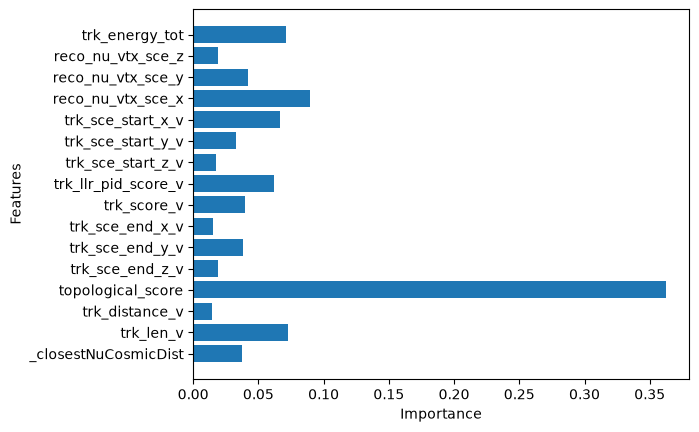

In [366]:
# Retrain the Exercise 6 background classifier after the energy cut.
from sklearn.preprocessing import StandardScaler

MC_EXT_ML_energy = MC_EXT_energy_selected.loc[
    MC_EXT_energy_selected['category'].isin([4, 5, 7, 31])
].copy()
X_energy = MC_EXT_ML_energy[features]
y_energy = MC_EXT_ML_energy['category'].to_numpy()
print('Energy-selected background training sample:', X_energy.shape)

x_train_energy, x_test_energy, y_train_energy, y_test_energy = train_test_split(
    X_energy, y_energy, test_size=0.2, random_state=1, stratify=y_energy
)

# Balance training classes by randomly undersampling to the smallest class.
# Keep the test set and the original physics samples at their natural proportions.
training_labels_energy = pd.Series(y_train_energy).reset_index(drop=True)
training_counts_energy = training_labels_energy.value_counts().sort_index()
if set(training_counts_energy.index) != {4, 5, 7, 31}:
    raise ValueError('Expected all four background classes: 4, 5, 7 and 31.')
rows_per_class_energy = int(training_counts_energy.min())
balanced_positions_energy = np.concatenate([
    training_labels_energy[training_labels_energy.eq(category)].sample(
        n=rows_per_class_energy, random_state=1
    ).index.to_numpy()
    for category in training_counts_energy.index
])
# Shuffle selected positions while preserving feature-label alignment.
balanced_positions_energy = np.random.default_rng(1).permutation(balanced_positions_energy)
x_train_energy = x_train_energy.iloc[balanced_positions_energy].copy()
y_train_energy = np.asarray(y_train_energy)[balanced_positions_energy]
print('Training class counts before balancing:')
print(training_counts_energy.to_string())
print('Training class counts after balancing:')
print(pd.Series(y_train_energy).value_counts().sort_index().to_string())

# Fit scaling statistics on the balanced training set only.
scaler_energy = StandardScaler()
x_train_energy = pd.DataFrame(
    scaler_energy.fit_transform(x_train_energy),
    columns=features, index=x_train_energy.index
)
x_test_energy = pd.DataFrame(
    scaler_energy.transform(x_test_energy),
    columns=features, index=x_test_energy.index
)

# Keep the original Exercise 6 model intact and train a separate model.
rf_energy = RandomForestClassifier(
    random_state=1, n_estimators=1000, max_depth=8,
    min_samples_split=5, min_samples_leaf=2, criterion='gini', n_jobs=-1
)
rf_energy.fit(x_train_energy, y_train_energy)
print('Training accuracy:', metrics.accuracy_score(
    y_train_energy, rf_energy.predict(x_train_energy)
))
print('Testing accuracy:', metrics.accuracy_score(
    y_test_energy, rf_energy.predict(x_test_energy)
))

feature_ranking_energy = pd.Series(
    rf_energy.feature_importances_, index=rf_energy.feature_names_in_,
    name='Importance'
).sort_values(ascending=False)
print('Feature importance after the energy cut:')
print(feature_ranking_energy.to_string())

# Plot feature importance using the same style as Exercise 6.
importance_energy = rf_energy.feature_importances_
plt.figure()
plt.barh(range(len(features)), importance_energy)
plt.yticks(range(len(features)), features)
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()

# The random split is by row; tracks from one event may appear in both sets.


In [367]:
def Selections(frame):
    
    # Basic variables present in dataframe 
    trk_start_x_v = frame['trk_sce_start_x_v']        # cm
    trk_start_y_v = frame['trk_sce_start_y_v']        # cm
    trk_start_z_v = frame['trk_sce_start_z_v']        # cm
    trk_end_x_v = frame['trk_sce_end_x_v']            # cm
    trk_end_y_v = frame['trk_sce_end_y_v']            # cm
    trk_end_z_v = frame['trk_sce_end_z_v']            # cm
    reco_x = frame['reco_nu_vtx_sce_x']               # cm
    reco_y = frame['reco_nu_vtx_sce_y']               # cm
    reco_z = frame['reco_nu_vtx_sce_z']               # cm
    topological = frame['topological_score']          # N/A
    trk_score_v = frame['trk_score_v']                # N/A
    trk_dis_v = frame['trk_distance_v']               # cm
    trk_len_v = frame['trk_len_v']                    # cm
    trk_energy_tot = frame['trk_energy_tot']          # GeV 
    
    
    
    # select the conditions you want to apply, here is an initial condition to get you started.
    selection =  ((trk_len_v > -1000) & (trk_len_v < 1000))
    
    # Apply selection on dataframe
    frame = frame[selection]
    
    return frame

## Calls the selection function on the dataframes

In [368]:
# Apply additional selections after the energy cut.
MC_EXT = Selections(MC_EXT_energy_selected)
data_frame = Selections(data_energy_selected)


# Plot all variables and decide on selection cuts
Here is the section with the example histogram plots for each variable. Create a new cell and implement your own function to plot all the histograms.

In [369]:
# Common variables in both dataframes
all_variables_to_plot = list(set(list(MC_EXT)).intersection(list(data_frame)))
print(all_variables_to_plot)


['reco_nu_vtx_sce_z', 'trk_range_muon_mom_v', 'trk_sce_end_z_v', 'trk_distance_v', 'trk_sce_end_y_v', 'topological_score', 'trk_len_v', 'reco_nu_vtx_sce_x', '_closestNuCosmicDist', 'trk_score_v', 'trk_energy_tot', 'trk_sce_start_y_v', 'category', 'trk_sce_end_x_v', 'trk_llr_pid_score_v', 'trk_sce_start_x_v', 'reco_nu_vtx_sce_y', 'trk_sce_start_z_v', 'trk_mcs_muon_mom_v']


In [ ]:
# Automatically select the top eight features from the energy-selected model.
# Run the rf_energy training cell above before this cell.
feature_ranking = pd.Series(
    rf_energy.feature_importances_,
    index=rf_energy.feature_names_in_,
    name='Importance'
).sort_values(ascending=False)

variables_to_plot = feature_ranking.head(8).index.tolist()
print('Top eight features selected from the trained model:')
print(feature_ranking.head(8).to_string())

# Keep category colours consistent with Exercise 5
category_palette = dict(zip(
    [4, 5, 7, 10, 21, 31],
    sns.color_palette('bright', 6)
))

# Descriptive labels for each category
category_names = {
    4: 'Mis-ID',
    5: 'Out Fid. Vol.',
    7: 'EXT',
    10: r'$\nu_e$ CC',
    21: r'$\nu_\mu$ CC',
    31: r'$\nu$ NC'
}

# Balance all present categories, including signal, for plotting only.
MC_hist_top8 = balanced_histogram_sample(MC_EXT)

# Create a grid containing eight plots
fig, axes = plt.subplots(4, 2, figsize=(16, 18))

# Plot the energy-selected sample with current additional cuts
for ax, variable in zip(axes.flat, variables_to_plot):
    sns.histplot(
        data=MC_hist_top8,
        x=variable,
        hue='category',
        palette=category_palette,
        multiple='stack',
        bins=40,
        ax=ax
    )

    ax.set_xlabel(variable)
    ax.set_ylabel('Entries (equal category sample sizes)')

    # Add category names to the numerical legend labels
    legend = ax.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            category = int(text.get_text())
            text.set_text(
                f'{category}: {category_names[category]}'
            )

plt.tight_layout()
plt.show()

### Cut scans for the top eight energy-selected random-forest features
Each panel scans one feature independently. Both cut directions are considered; the displayed direction maximises purity while retaining at least 80% of the weighted signal rows remaining after the energy cut. Coordinate features may need two-sided fiducial cuts instead. These suggestions are not applied automatically.


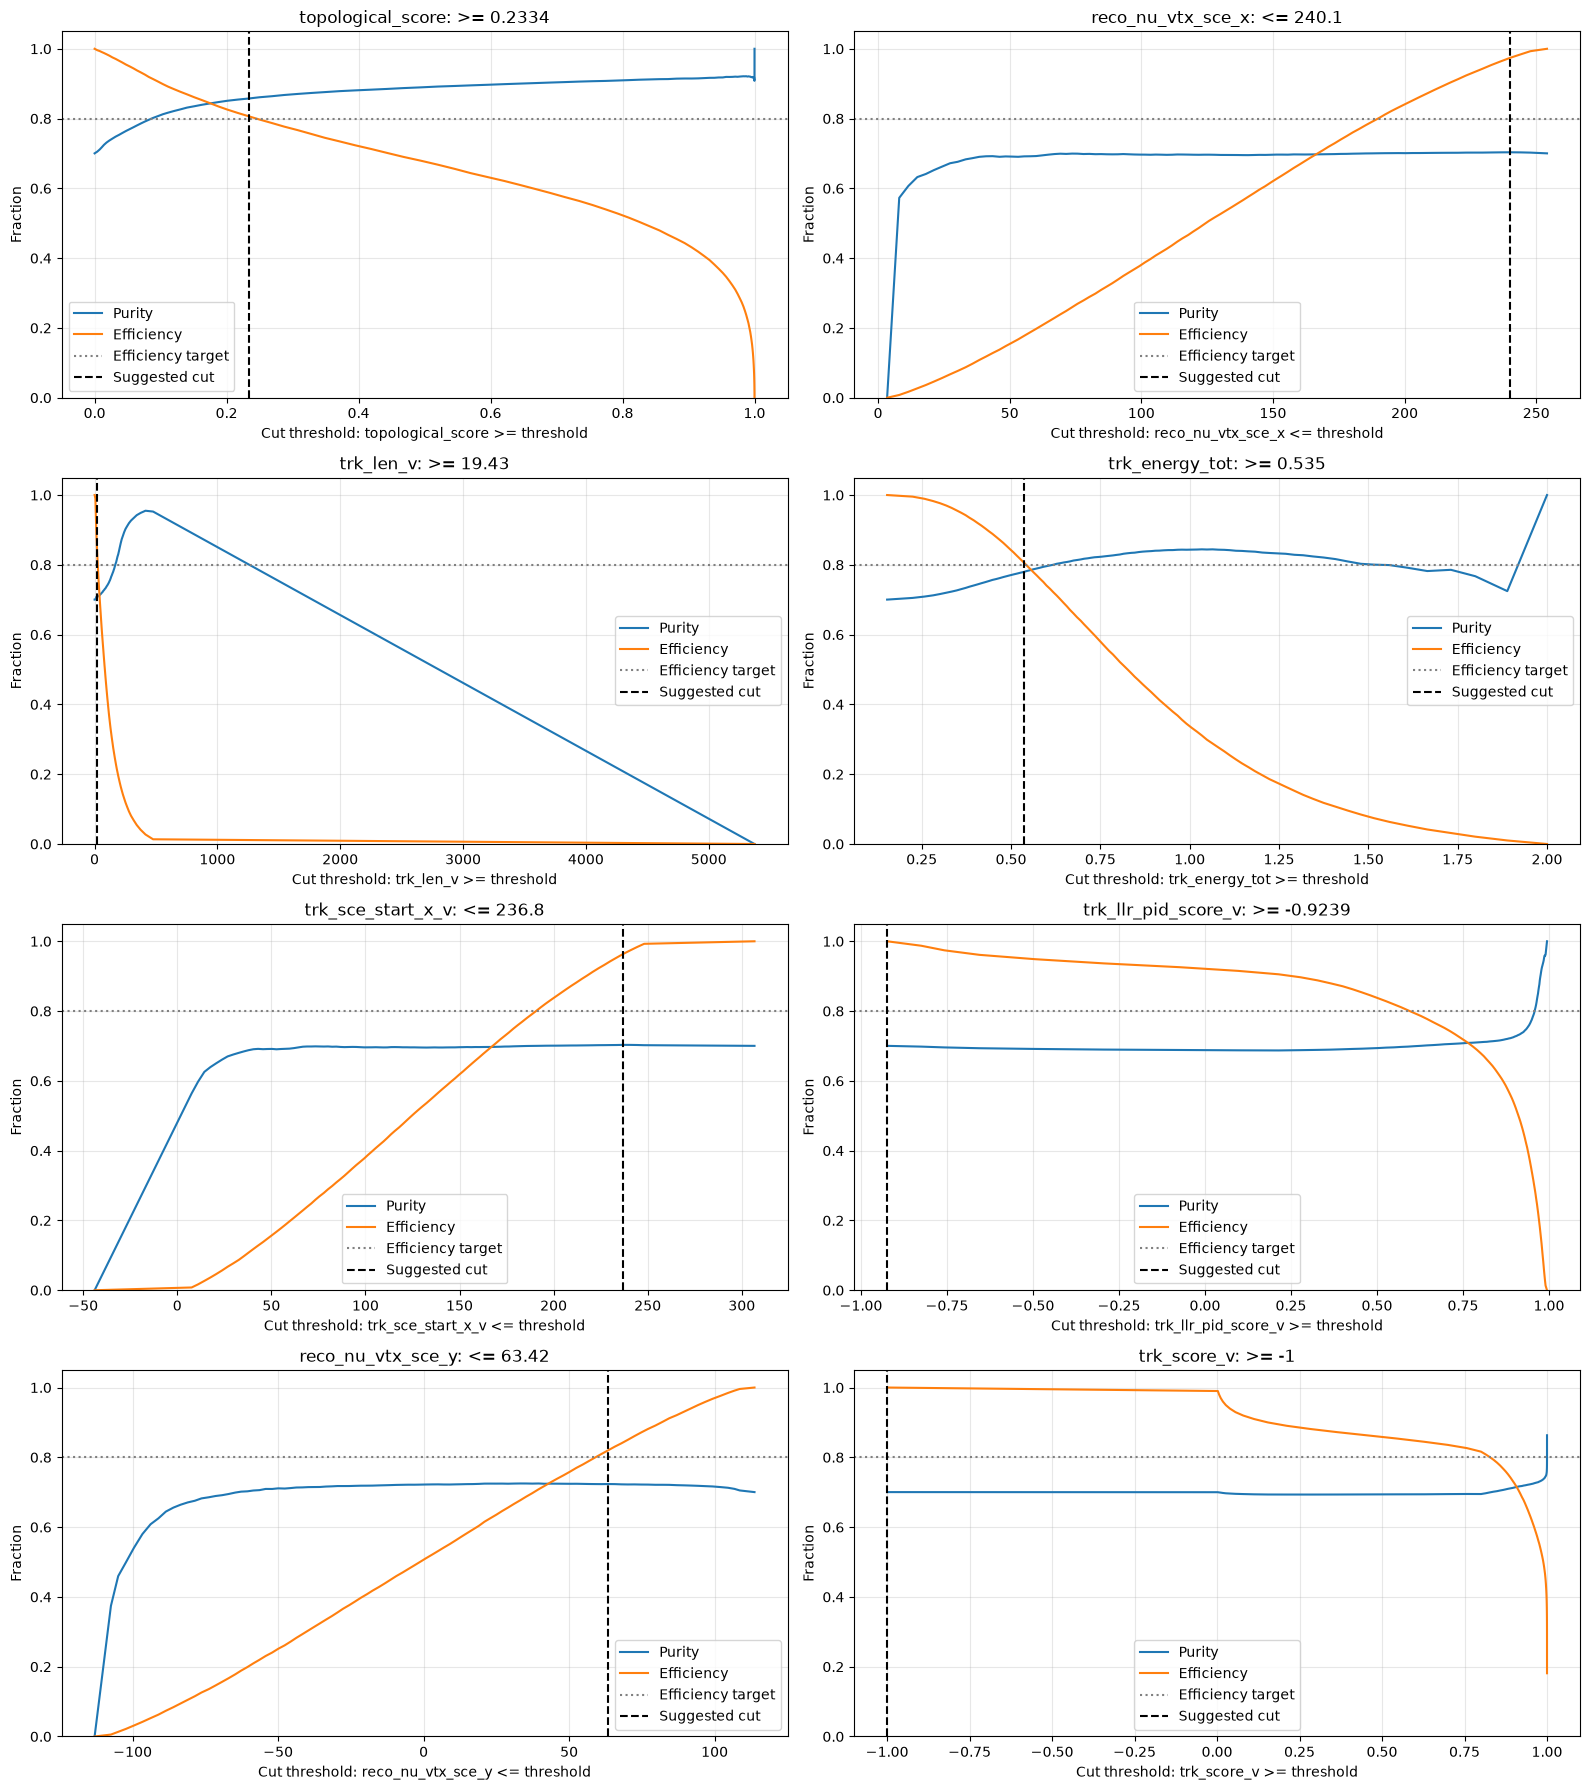

Suggested independent cuts (not automatically applied):
           variable direction  threshold   purity  efficiency
  topological_score        >=   0.233439 0.857489    0.806620
  reco_nu_vtx_sce_x        <= 240.088828 0.703416    0.974099
          trk_len_v        >=  19.429859 0.709588    0.853563
     trk_energy_tot        >=   0.535032 0.779502    0.807381
  trk_sce_start_x_v        <= 236.837988 0.703147    0.963364
trk_llr_pid_score_v        >=  -0.923938 0.700335    1.000000
  reco_nu_vtx_sce_y        <=  63.417377 0.723436    0.820135
        trk_score_v        >=  -1.000000 0.700335    1.000000


In [371]:
# Scan each of the same eight features independently in original physical units.
# These are weighted-row metrics, not unique-event metrics.
# Efficiency is relative to the signal remaining after the energy cut.
# Importance from the energy-selected background classifier does not guarantee signal separation.
frame = MC_EXT_energy_selected
signal = frame['category'].eq(21).to_numpy()
weights = frame['weight'].to_numpy(dtype=float)
if not np.isfinite(weights).all() or (weights < 0).any():
    raise ValueError('This scan requires finite, non-negative weights.')
signal_before = weights[signal].sum()
if signal_before <= 0:
    raise ValueError('No positive total signal weight in the original sample.')

minimum_efficiency = 0.80  # Illustrative requirement, not a prescribed target.
cut_scans = {}
cut_summary_rows = []
fig, axes = plt.subplots(4, 2, figsize=(16, 18))

for ax, variable in zip(axes.flat, variables_to_plot):
    values = pd.to_numeric(frame[variable], errors='coerce').to_numpy(dtype=float)
    valid = np.isfinite(values)
    if not valid.any():
        ax.set_title(variable + ': no finite values')
        continue

    # Include the finite range boundaries and quantiles to cover the distribution.
    thresholds = np.unique(np.quantile(values[valid], np.linspace(0, 1, 101)))
    order = np.argsort(values[valid])
    sorted_values = values[valid][order]
    sorted_weights = weights[valid][order]
    sorted_signal = signal[valid][order]
    total_prefix = np.r_[0.0, np.cumsum(sorted_weights)]
    signal_prefix = np.r_[0.0, np.cumsum(sorted_weights * sorted_signal)]
    scans = []

    for direction in ['>=', '<=']:
        # Cumulative sums evaluate all thresholds without repeated dataframe copies.
        if direction == '>=':
            idx = np.searchsorted(sorted_values, thresholds, side='left')
            total_after = total_prefix[-1] - total_prefix[idx]
            signal_after = signal_prefix[-1] - signal_prefix[idx]
        else:
            idx = np.searchsorted(sorted_values, thresholds, side='right')
            total_after = total_prefix[idx]
            signal_after = signal_prefix[idx]

        purity = np.divide(signal_after, total_after,
                           out=np.full_like(total_after, np.nan), where=total_after > 0)
        scans.append(pd.DataFrame({
            'threshold': thresholds, 'direction': direction,
            'purity': purity, 'efficiency': signal_after / signal_before
        }))

    table = pd.concat(scans, ignore_index=True)
    cut_scans[variable] = table
    candidates = table[
        (table['efficiency'] >= minimum_efficiency) & table['purity'].notna()
    ]
    if candidates.empty:
        ax.set_title(variable + ': no cut meets the efficiency target')
        ax.set_visible(True)
        continue

    # Choose the direction and threshold with highest purity at the required efficiency.
    best = candidates.sort_values(
        ['purity', 'efficiency'], ascending=False
    ).iloc[0]
    direction = best['direction']
    displayed = table[table['direction'] == direction]
    ax.plot(displayed['threshold'], displayed['purity'], label='Purity')
    ax.plot(displayed['threshold'], displayed['efficiency'], label='Efficiency')
    ax.axhline(minimum_efficiency, color='grey', linestyle=':', label='Efficiency target')
    ax.axvline(best['threshold'], color='black', linestyle='--', label='Suggested cut')
    ax.set_title(f"{variable}: {direction} {best['threshold']:.4g}")
    ax.set_xlabel(f'Cut threshold: {variable} {direction} threshold')
    ax.set_ylabel('Fraction')
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()
    cut_summary_rows.append({
        'variable': variable, 'direction': direction,
        'threshold': best['threshold'], 'purity': best['purity'],
        'efficiency': best['efficiency']
    })

plt.tight_layout()
plt.show()
cut_summary = pd.DataFrame(cut_summary_rows)
print('Suggested independent cuts (not automatically applied):')
print(cut_summary.to_string(index=False))
# Re-evaluate purity and efficiency after combining cuts in Selections.


# Exercise 8: Check the purity and efficiency of the sample
It is recommended to plot purity and efficiency after each variable cut.

**HINT:** Function Selection() has commented lines of code that you may find useful for purpose of plotting changes in purity/efficiency after every cut.

# Exercise 9: Plot the energy spectrums here and normalise

Final representation of MC and data after applying the cuts.

# Exercise 10: Oscillation and fitting

### a) Define functions requires for Oscillation analysis, test that they work!


In [372]:
# oscillation function


In [373]:
# muon disappearance application to reconstructed neutrino energy


In [374]:
# chi squared function


# Exercise 11/12: Oscillation parameter scan, contour plotting, closure test.

### Closure test, create your oscillation parameter scanning code, and find minimum values for chi squared!

In [375]:
# Selection cuts on oscillated data

In [376]:
# Function that oscillates and calculates chi squared for set delM21 and sin^2(2theta)

In [377]:
# Function that loops the above function across range of values of delM21 and sin^2(2theta)

In [378]:
# plot contourf function and find minimum!

Apply your above defined functions, and represent your result with matplotlib's contour and fcontour.

In [379]:
# oscillate MC wrt to true data

In [380]:
# contourf application

### Bonus: Minimise

Minimise your chi square value, determining the parameters of 'best fit'

### Confidence levels and parameter minima. 
Determine confidence levels, and find the parameter values that correspond to the lowest chi squared value within your range.with

In [381]:
# contour application, with correct confidence levels.

In [382]:
# find lowest chi squared value within range and plot with CL, or contourf plot.

# Exercise 13/14: 3+1 Framework Neutrino disappearance.

In [383]:
# Produce your new oscillation parameter, which should be sin^2(2*theta_ue)

# Compare your result with MiniBooNE

Results are extracted from MiniBooNE (orange) and LSND (blue)

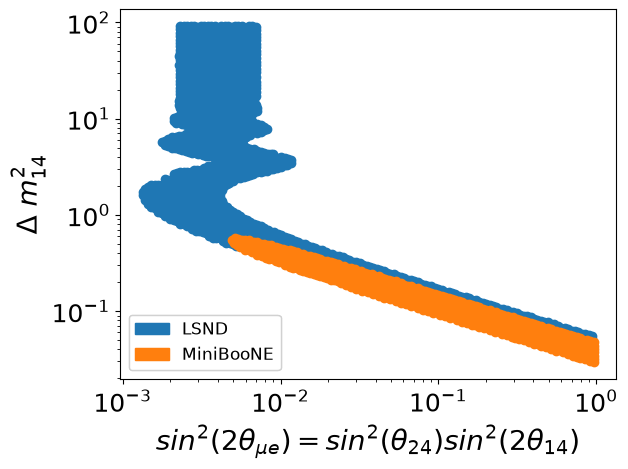

In [384]:
# Load data
LSND_data = pd.read_csv('./data/DataSet_LSND.csv').to_numpy()
MiniBooNE_data = pd.read_csv('./data/DataSet_MiniBooNE.csv').to_numpy()

# Plot data
plt.plot(LSND_data[:,0],LSND_data[:,1],'o')
plt.plot(MiniBooNE_data[:,0],MiniBooNE_data[:,1],'o')

# Producing MiniBooNE/LSND legend
LSND_path = mpatches.Patch(color='tab:blue', label = 'LSND')
MINI_path = mpatches.Patch(color='tab:orange', label = 'MiniBooNE')
first_legend = plt.legend(handles=[LSND_path, MINI_path], loc = 'lower left', fontsize = 12)
plt.gca().add_artist(first_legend)


plt.xlabel(r'$sin^2(2\theta_{\mu e})=sin^2(\theta_{24})sin^2(2\theta_{14})$',fontsize=20)
plt.ylabel(r'$\Delta$ $m_{14}^2$',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.yscale('log')
plt.xscale('log')
plt.show()